In [ ]:
import pandas as pd
from NVE_API import get_nve_data
import matplotlib.pyplot as plt


# IND320 – Project 2

## Data Engineering with APIs, Apache Spark, Cassandra and MongoDB

### Project overview

This project explores a data engineering workflow using electricity-related datasets from Norway.

The project includes two data sources:

1. **NVE API:** Norwegian reservoir filling levels.
2. **ENTSO-E API:** Cross-border electricity imports and exports.

The workflow uses:
- Python for API data collection
- Apache Spark for data processing
- Apache Cassandra for storing electricity transfer observations
- MongoDB Atlas for storing aggregated data
- Streamlit for interactive visualization

**Current status:** The NVE API uses real observations. The ENTSO-E workflow has been tested with synthetic data while waiting for API access.

## 1. NVE API – Norwegian Reservoir Data

The Norwegian Water Resources and Energy Directorate (NVE) provides public reservoir statistics through an API.

In this section, we retrieve real reservoir data using Python and inspect the dataset before further analysis.

The API data will also be used in the Streamlit dashboard.

In [3]:
# Retrieve reservoir data from NVE API
df_nve = get_nve_data()

# Inspect the dataset
print("Dataset shape:", df_nve.shape)

display(df_nve.head())

Dataset shape: (14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


## 2. Exploratory Data Analysis (EDA)

Before visualizing the reservoir data, we examine the dataset's structure, time coverage, area types, and missing values.

This helps us understand the data quality and determine how the observations should be grouped.

In [4]:
# Check data types
print("Data types:")
print(df_nve.dtypes)

# Check missing values
print("\nMissing values:")
print(df_nve.isna().sum())

# Check available area types
print("\nArea types:")
print(df_nve["omrType"].value_counts())

# Check time coverage
df_nve["dato_Id"] = pd.to_datetime(df_nve["dato_Id"])

print("\nDate range:")
print("From:", df_nve["dato_Id"].min())
print("To:", df_nve["dato_Id"].max())

Data types:
dato_Id                     datetime64[ns]
omrType                             object
omrnr                                int64
iso_aar                              int64
iso_uke                              int64
fyllingsgrad                       float64
kapasitet_TWh                      float64
fylling_TWh                        float64
neste_Publiseringsdato              object
fyllingsgrad_forrige_uke           float64
endring_fyllingsgrad               float64
dtype: object

Missing values:
dato_Id                     0
omrType                     0
omrnr                       0
iso_aar                     0
iso_uke                     0
fyllingsgrad                0
kapasitet_TWh               0
fylling_TWh                 0
neste_Publiseringsdato      0
fyllingsgrad_forrige_uke    0
endring_fyllingsgrad        0
dtype: int64

Area types:
omrType
EL      8290
VASS    4974
NO      1658
Name: count, dtype: int64

Date range:
From: 1995-01-08 00:00:00
To: 2026-10-11 0

In [5]:
# Number of unique areas within each area type
area_summary = (
    df_nve.groupby("omrType")["omrnr"]
    .nunique()
    .reset_index(name="number_of_areas")
)

display(area_summary)

# Show area numbers within each type
for area_type, group in df_nve.groupby("omrType"):
    print(f"\nArea type: {area_type}")
    print("Area numbers:", sorted(group["omrnr"].unique()))

,omrType,number_of_areas
0,EL,5
1,NO,1
2,VASS,3



Area type: EL
Area numbers: [1, 2, 3, 4, 5]

Area type: NO
Area numbers: [0]

Area type: VASS
Area numbers: [1, 2, 3]


## 3. Reservoir Filling Levels Over Time

We visualize the development of reservoir filling levels across Norwegian electricity price areas (EL), as an example.

Each line represents one area. This allows us to compare seasonal patterns and differences between regions.

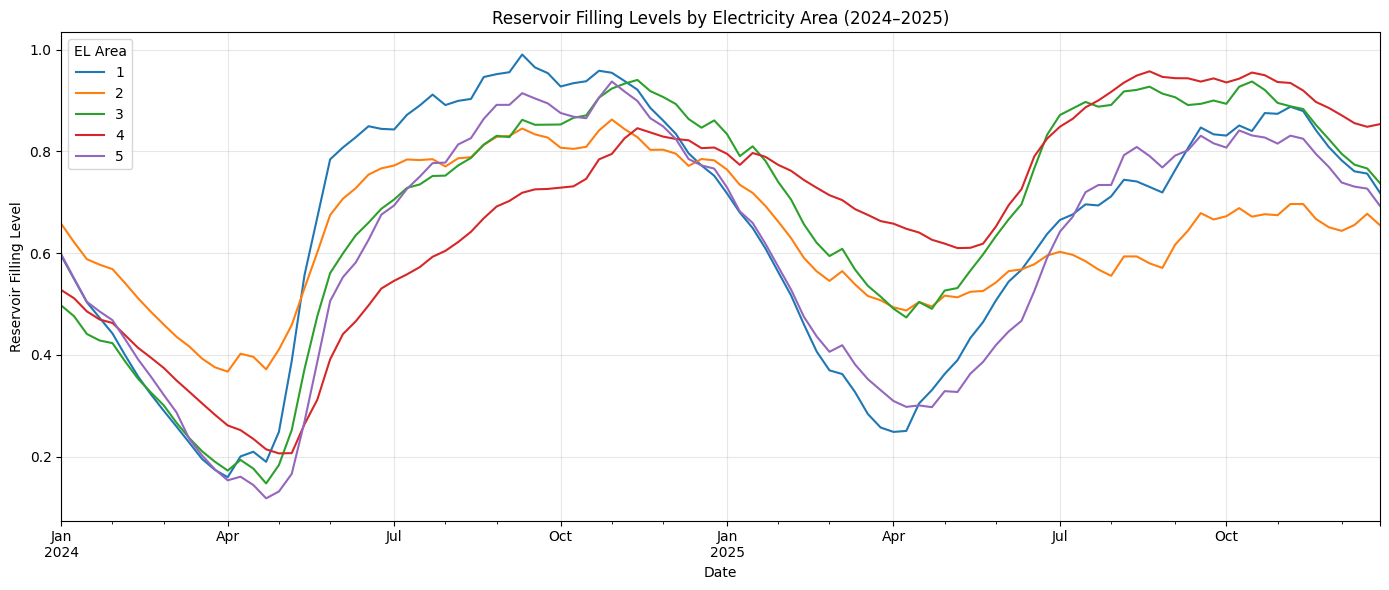

In [ ]:

# Select EL areas
df_el = df_nve[df_nve["omrType"] == "EL"].copy()

# Focus on the last two complete calendar years
df_el = df_el[
    (df_el["dato_Id"] >= "2024-01-01") &
    (df_el["dato_Id"] < "2026-01-01")
]

# Pivot: one column per area
df_plot = df_el.pivot_table(
    index="dato_Id",
    columns="omrnr",
    values="fyllingsgrad",
    aggfunc="mean"
)

# Plot
ax = df_plot.plot(figsize=(14, 6))

ax.set_title("Reservoir Filling Levels by Electricity Area (2024–2025)")
ax.set_xlabel("Date")
ax.set_ylabel("Reservoir Filling Level")
ax.legend(title="EL Area")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The figure shows some seasonal patterns in reservoir filling levels across the five electricity areas during 2024–2025. Filling levels generally decrease during winter and spring before increasing during summer and autumn. There are also noticeable regional differences, particularly in 2025, when EL4 maintains higher filling levels than several other areas.

## 4. Apache Spark and Cassandra

Apache Spark is used for distributed data processing, while Apache Cassandra provides storage for electricity transfer observations.

In this project, both services run in Docker containers. The Spark Cassandra Connector enables Spark to write data to and read data from Cassandra.

The workflow is tested using synthetic ENTSO-E data while waiting for API access.

### 4.1 Testing the Spark–Cassandra Connection

To verify the data pipeline, I generated synthetic electricity transfer observations for nine Norwegian cross-border connections.

Apache Spark was used to process the data and write it to the Cassandra table `ind320.entsoe_test`.

The data was then read back into Spark to verify that the connection and storage worked correctly.

**Result:** 432 observations were successfully retrieved from Cassandra.

The test confirms that Spark can communicate with Cassandra and that the data can be stored and retrieved.

In [7]:
# Spark and Cassandra integration
# Executed in Docker using ENTSOE_Spark.py

spark_command = """
docker cp ENTSOE_Spark.py spark-cassandra:/tmp/ENTSOE_Spark.py

docker exec spark-cassandra /opt/spark/bin/spark-submit \
    --conf spark.jars.ivy=/tmp/ivy2 \
    --packages com.datastax.spark:spark-cassandra-connector_2.12:3.5.1 \
    --conf spark.cassandra.connection.host=cassandra-db \
    /tmp/ENTSOE_Spark.py
"""

print(spark_command)


docker cp ENTSOE_Spark.py spark-cassandra:/tmp/ENTSOE_Spark.py

docker exec spark-cassandra /opt/spark/bin/spark-submit     --conf spark.jars.ivy=/tmp/ivy2     --packages com.datastax.spark:spark-cassandra-connector_2.12:3.5.1     --conf spark.cassandra.connection.host=cassandra-db     /tmp/ENTSOE_Spark.py



### 4.2 Results

- Number of cross-border connections: 9
- Number of synthetic observations: 432
- Cassandra keyspace: `ind320`
- Cassandra table: `entsoe_test`
- Spark version: 3.5.1

The observations were successfully written to Cassandra and read back using Apache Spark.

Spark was also used to aggregate the observations by connection and month, producing nine monthly summary records.

### 4.3 Monthly Aggregation Using Apache Spark

After retrieving the observations from Cassandra, Apache Spark was used to aggregate electricity imports and exports by connection and month.

The aggregation calculates:
- Total monthly electricity imports (MWh)
- Total monthly electricity exports (MWh)

The resulting dataset contains one row per connection and month.

Since the current test dataset covers only October 2026, the aggregation produces nine records, one for each cross-border connection.

### 4.4 Storing Aggregated Data in MongoDB Atlas

After processing the data in Spark, the monthly aggregated results were exported to a JSON file.

The JSON file was then loaded into MongoDB Atlas using Python and PyMongo.

Database: `IND320`  
Collection: `entsoe_monthly_test`

The nine aggregated test records were successfully stored in MongoDB Atlas and retrieved using Python.

The Streamlit dashboard reads these records from MongoDB to visualize electricity imports and exports.

**Note:** These records contain synthetic test data, not actual ENTSO-E observations.

**SUMMARY**

Spark → Cassandra

- 432 observations successfully stored and retrieved

Spark Aggregation

- 9 monthly summary records generated

MongoDB Atlas

- 9 documents stored

## 5. Streamlit Dashboard

A Streamlit application was developed to visualize reservoir statistics and cross-border electricity transfers.

## 6. Project log

The project focused on building a data engineering pipeline for Norwegian electricity and reservoir data using Python, Apache Spark, Cassandra, MongoDB Atlas and Streamlit.

I started by setting up Apache Cassandra and Spark in Docker containers. One challenge was ensuring compatibility between Spark, Scala and the Cassandra connector. After testing different configurations, I established a working connection using Spark 3.5.1 and the corresponding Cassandra connector.

Next, I implemented data collection from the NVE API. Instead of relying on downloaded CSV files, I developed a Python function to retrieve reservoir statistics directly from the API. I explored the dataset, checked data types and missing values, and visualized reservoir filling levels across Norwegian electricity areas.

For the ENTSO-E component, I registered on the Transparency Platform and requested an API token. Since access was still pending, I created synthetic observations to test the technical pipeline. These observations were processed using Spark, stored in Cassandra and read back to verify the integration. I then used Spark to calculate monthly import and export totals for each cross-border connection.

The aggregated results were exported to JSON and uploaded to MongoDB Atlas using PyMongo. I verified that the documents could be retrieved successfully.

Finally, I developed Streamlit visualizations for both datasets. The NVE dashboard allows users to explore reservoir levels across different area types, while the electricity transfers dashboard provides import/export pie charts and monthly comparisons.

### Use of AI

I used AI as a learning and debugging assistant throughout the entire project. It helped me understand technical concepts, troubleshoot Python and Docker errors, structure functions and organize the notebook documentation.

I ran the code, inspected the results and adjusted the implementation when necessary. 
AI was particularly useful for breaking complex integration tasks into smaller, manageable steps.